In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna().reset_index(drop=True)

X = df.drop("target", axis=1).values.astype(float)
y = np.where(df["target"].values == 1, 1, -1)

print("Dataset Shape:", df.shape)
print("Class Distribution:", pd.Series(y).value_counts())

Dataset Shape: (302, 14)
Class Distribution:  1    164
-1    138
Name: count, dtype: int64


In [3]:
def split_data(X, y, test_size=0.2, seed=42):

    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []

    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)

        split = int(len(idx) * (1 - test_size))
        train_idx.extend(idx[:split])
        test_idx.extend(idx[split:])

    train_idx = np.array(train_idx)
    test_idx = np.array(test_idx)

    rng.shuffle(train_idx)
    rng.shuffle(test_idx)

    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


X_train, X_test, y_train, y_test = split_data(X, y)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (241, 13)
Testing Shape: (61, 13)


In [4]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

In [5]:
def polynomial_kernel(X1, X2, degree=3, gamma=0.01, coef0=1):

    return (gamma * (X1 @ X2.T) + coef0) ** degree


poly_kernel = polynomial_kernel(X_train, X_train)

print("Polynomial Kernel Matrix Shape:", poly_kernel.shape)

Polynomial Kernel Matrix Shape: (241, 241)


In [6]:
def rbf_kernel(X1, X2, gamma=0.01):

    distances = (
        np.sum(X1 ** 2, axis=1).reshape(-1, 1)
        + np.sum(X2 ** 2, axis=1)
        - 2 * (X1 @ X2.T)
    )

    return np.exp(-gamma * np.maximum(distances, 0))


rbf = rbf_kernel(X_train, X_train)

print("RBF Kernel Matrix Shape:", rbf.shape)

RBF Kernel Matrix Shape: (241, 241)


In [7]:
def train_kernel_svm(K, y, C=1, max_passes=5, max_iterations=1000):

    n = len(y)
    alpha = np.zeros(n)
    bias = 0
    passes = 0
    iterations = 0
    tolerance = 1e-3

    while passes < max_passes and iterations < max_iterations:

        changed = 0

        for i in range(n):

            error_i = np.sum(alpha * y * K[:, i]) + bias - y[i]

            if not ((y[i] * error_i < -tolerance and alpha[i] < C)
                    or (y[i] * error_i > tolerance and alpha[i] > 0)):
                continue

            candidates = np.where(np.arange(n) != i)[0]
            j = candidates[np.argmax(np.abs(
                error_i - (np.sum(alpha * y * K[candidates], axis=1) + bias - y[candidates])
            ))]

            error_j = np.sum(alpha * y * K[:, j]) + bias - y[j]

            old_i, old_j = alpha[i], alpha[j]

            if y[i] != y[j]:
                L = max(0, alpha[j] - alpha[i])
                H = min(C, C + alpha[j] - alpha[i])
            else:
                L = max(0, alpha[i] + alpha[j] - C)
                H = min(C, alpha[i] + alpha[j])

            if L == H:
                continue

            eta = 2 * K[i, j] - K[i, i] - K[j, j]

            if eta >= 0:
                continue

            alpha[j] -= y[j] * (error_i - error_j) / eta
            alpha[j] = np.clip(alpha[j], L, H)

            if abs(alpha[j] - old_j) < 1e-5:
                alpha[j] = old_j
                continue

            alpha[i] += y[i] * y[j] * (old_j - alpha[j])

            b1 = (bias - error_i
                  - y[i] * (alpha[i] - old_i) * K[i, i]
                  - y[j] * (alpha[j] - old_j) * K[i, j])

            b2 = (bias - error_j
                  - y[i] * (alpha[i] - old_i) * K[i, j]
                  - y[j] * (alpha[j] - old_j) * K[j, j])

            if 0 < alpha[i] < C:
                bias = b1
            elif 0 < alpha[j] < C:
                bias = b2
            else:
                bias = (b1 + b2) / 2

            changed += 1

        passes = passes + 1 if changed == 0 else 0
        iterations += 1

    return alpha, bias


print("SMO training function ready.")

SMO training function ready.


In [8]:
poly_train_kernel = polynomial_kernel(
    X_train, X_train, degree=3, gamma=0.01
)

poly_alpha, poly_bias = train_kernel_svm(
    poly_train_kernel, y_train, C=1,
    max_passes=5, max_iterations=100
)

poly_support = poly_alpha > 1e-5

print("Polynomial SVM Training Completed")
print("Support Vectors:", np.sum(poly_support))

Polynomial SVM Training Completed
Support Vectors: 26


In [9]:
rbf_train_kernel = rbf_kernel(X_train, X_train, gamma=0.01)

rbf_alpha, rbf_bias = train_kernel_svm(
    rbf_train_kernel, y_train, C=1,
    max_passes=5, max_iterations=100
)

rbf_support = rbf_alpha > 1e-5

print("RBF SVM Training Completed")
print("Support Vectors:", np.sum(rbf_support))

RBF SVM Training Completed
Support Vectors: 20


In [10]:
def predict_kernel_svm(X_train, X_test, y_train, alpha, bias, kernel_function):

    K_test = kernel_function(X_test, X_train)

    scores = K_test @ (alpha * y_train) + bias

    return np.where(scores >= 0, 1, -1)


poly_predictions = predict_kernel_svm(
    X_train, X_test, y_train, poly_alpha, poly_bias,
    lambda a, b: polynomial_kernel(a, b, degree=3, gamma=0.01)
)

rbf_predictions = predict_kernel_svm(
    X_train, X_test, y_train, rbf_alpha, rbf_bias,
    lambda a, b: rbf_kernel(a, b, gamma=0.01)
)

print("Actual Labels:     ", y_test[:10])
print("Polynomial Results:", poly_predictions[:10])
print("RBF Results:       ", rbf_predictions[:10])

Actual Labels:      [-1  1 -1  1 -1 -1  1  1  1  1]
Polynomial Results: [-1  1  1 -1 -1 -1  1  1  1  1]
RBF Results:        [-1 -1 -1 -1 -1 -1  1 -1  1  1]


In [11]:
def calculate_accuracy(y_true, y_pred):

    correct = sum(y_true == y_pred)

    return correct / len(y_true) * 100


poly_accuracy = calculate_accuracy(y_test, poly_predictions)
rbf_accuracy = calculate_accuracy(y_test, rbf_predictions)

print("Polynomial SVM Accuracy:", round(poly_accuracy, 2), "%")
print("RBF SVM Accuracy:", round(rbf_accuracy, 2), "%")

Polynomial SVM Accuracy: 80.33 %
RBF SVM Accuracy: 65.57 %


In [12]:
support_comparison = pd.DataFrame({
    "Kernel": ["Polynomial", "Polynomial", "RBF", "RBF"],
    "Class": [-1, 1, -1, 1],
    "Support Vectors": [
        np.sum(poly_support & (y_train == -1)),
        np.sum(poly_support & (y_train == 1)),
        np.sum(rbf_support & (y_train == -1)),
        np.sum(rbf_support & (y_train == 1))
    ]
})

display(support_comparison)

,Kernel,Class,Support Vectors
0,Polynomial,-1,13
1,Polynomial,1,13
2,RBF,-1,10
3,RBF,1,10


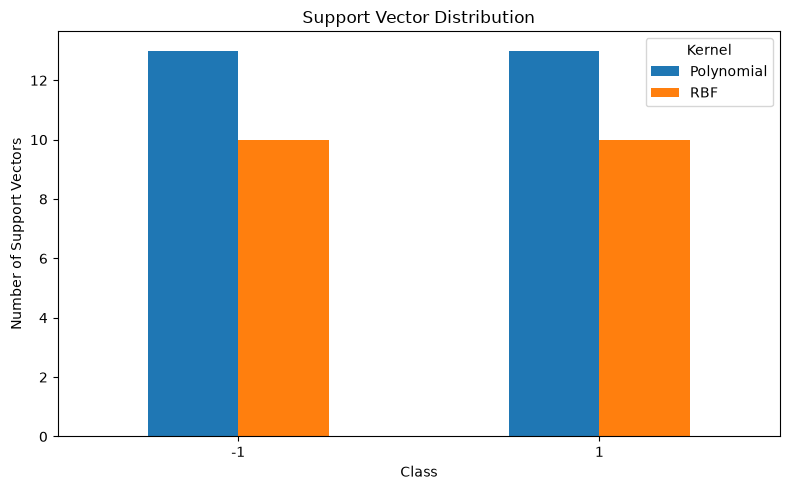

In [13]:
support_pivot = support_comparison.pivot(
    index="Class",
    columns="Kernel",
    values="Support Vectors"
)

support_pivot.plot(kind="bar", figsize=(8, 5))

plt.title("Support Vector Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Support Vectors")
plt.xticks(rotation=0)
plt.legend(title="Kernel")
plt.tight_layout()
plt.show()

,Kernel,Accuracy (%),Total Support Vectors
0,Polynomial,80.327869,26
1,RBF,65.573770,20


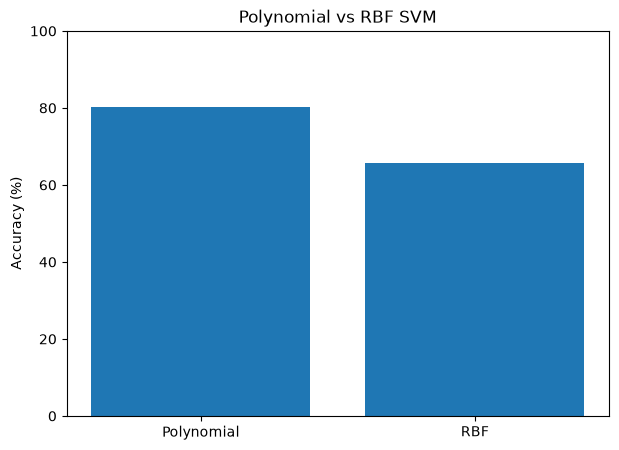

In [14]:
comparison = pd.DataFrame({
    "Kernel": ["Polynomial", "RBF"],
    "Accuracy (%)": [poly_accuracy, rbf_accuracy],
    "Total Support Vectors": [
        np.sum(poly_support),
        np.sum(rbf_support)
    ]
})

display(comparison)

plt.figure(figsize=(7, 5))
plt.bar(comparison["Kernel"], comparison["Accuracy (%)"])

plt.title("Polynomial vs RBF SVM")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()

## Conclusion

In this task, Polynomial and RBF kernels were manually implemented
for Support Vector Machine classification.

The kernel trick was applied using manually calculated kernel
matrices, and the SMO algorithm was implemented to optimize the
soft-margin SVM dual problem.

Both kernel models were evaluated using manually calculated
accuracy. Their support vector counts and class-wise distributions
were also compared.

The results demonstrate how different kernel functions can
affect SVM classification performance and support vector selection.